In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random
import os

import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn

from torchvision import models, transforms
from PIL import Image
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances, manhattan_distances
from sklearn.manifold import MDS

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed = 0

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [5]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [6]:
set_seed(seed)
def load_images(folder, num_images=200):
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

    all_filenames = [filename for filename in os.listdir(folder) if filename.lower().endswith(valid_extensions)]

    if len(all_filenames) == 0:
        raise ValueError(f'No images found in {folder}')

    random_filenames = random.sample(all_filenames, min(num_images, len(all_filenames)))

    images = []
    filenames = []

    for filename in random_filenames:
        img_path = os.path.join(folder, filename)

        with Image.open(img_path) as img:
            img = img.convert('RGB')
            img = transform(img)

        images.append(img)
        filenames.append(filename)

    return torch.stack(images), filenames

In [7]:
set_seed(seed)
images, filenames = load_images('oxbuilding', num_images=200)

print(f'Number of images: {len(filenames)}')
print(f'Image tensor shape: {images.shape}')

Number of images: 200
Image tensor shape: torch.Size([200, 3, 224, 224])


In [8]:
weights_path = os.path.join(torch.hub.get_dir(), "checkpoints", "resnet50-0676ba61.pth")

model = models.resnet50(weights=None)
model.load_state_dict(torch.load(weights_path, map_location='cpu'))

model = nn.Sequential(*list(model.children())[:-1])
model = model.to(device)
model.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [9]:
with torch.no_grad():
    images_device = images.to(device)
    features = model(images_device).flatten(1)

features = features.cpu().numpy()

print(f'Feature matrix shape: {features.shape}')

Feature matrix shape: (200, 2048)


In [10]:
def compute_distances(X, metric):
    if metric == 'euclidean':
        return euclidean_distances(X)
    elif metric == 'cosine':
        return cosine_distances(X)
    elif metric == 'manhattan':
        return manhattan_distances(X)
    else:
        raise ValueError(f'Unknown metric: {metric}')

In [11]:
distance_metrics = ['euclidean', 'cosine', 'manhattan']

distance_matrices = {metric: compute_distances(features, metric) for metric in distance_metrics}

In [12]:
mds_results = {}

for metric in distance_metrics:
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)

    mds_results[metric] = mds.fit_transform(distance_matrices[metric])

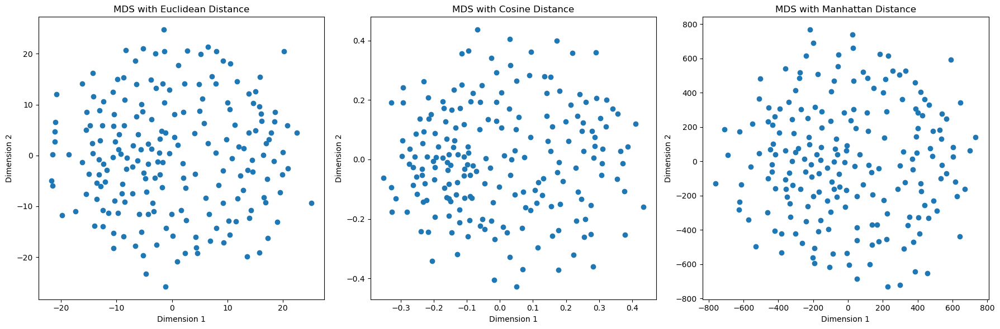

In [13]:
plt.figure(figsize=(18, 6))

for i, metric in enumerate(distance_metrics):
    plt.subplot(1, 3, i + 1)

    plt.scatter(mds_results[metric][:, 0], mds_results[metric][:, 1])

    plt.title(f'MDS with {metric.capitalize()} Distance')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')

plt.tight_layout()
plt.show()

In [14]:
def retrieve_similar_images(image_idx, metric, top_n=5):
    distances = distance_matrices[metric][image_idx].copy()

    distances[image_idx] = np.inf

    similar_indices = np.argsort(distances)[:top_n]

    return similar_indices

In [15]:
def display_images(image_idx, similar_indices, images, filenames, metric):
    indices = [image_idx] + list(similar_indices)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    plt.figure(figsize=(20, 5))
    plt.suptitle(
        f'Similar Images using {metric.capitalize()} Distance', fontsize=16)

    for i, idx in enumerate(indices):
        plt.subplot(1, len(indices), i + 1)

        img = images[idx].permute(1, 2, 0).numpy()
        img = img * std + mean
        img = np.clip(img, 0, 1)

        plt.imshow(img)

        if i == 0:
            plt.title(f'Query\n{filenames[idx]}')
        else:
            plt.title(f'Result {i}\n{filenames[idx]}')

        plt.axis('off')

    plt.tight_layout()
    plt.show()

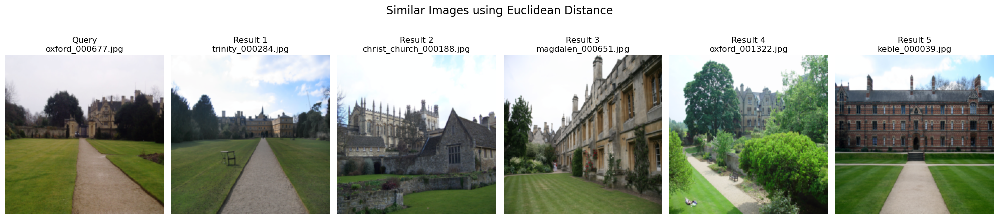

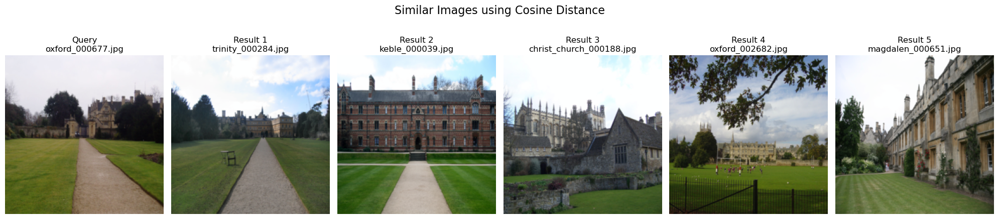

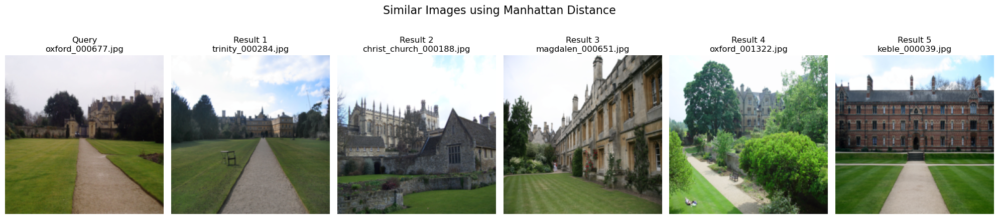

In [16]:
image_idx = 0

for metric in distance_metrics:
    similar_images = retrieve_similar_images(image_idx, metric, top_n=5)

    display_images(image_idx, similar_images, images, filenames, metric)

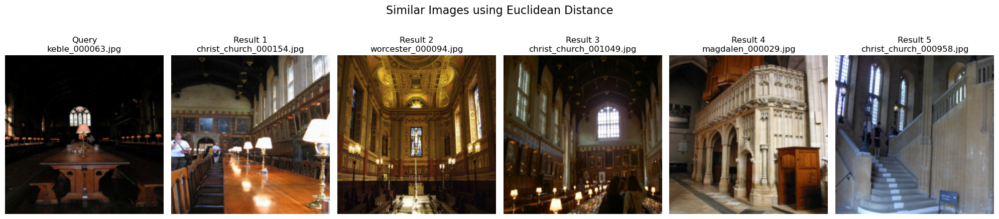

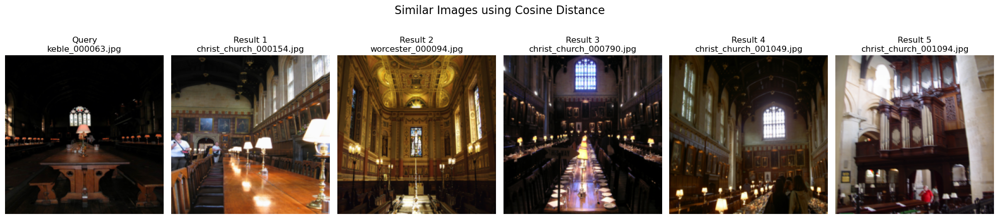

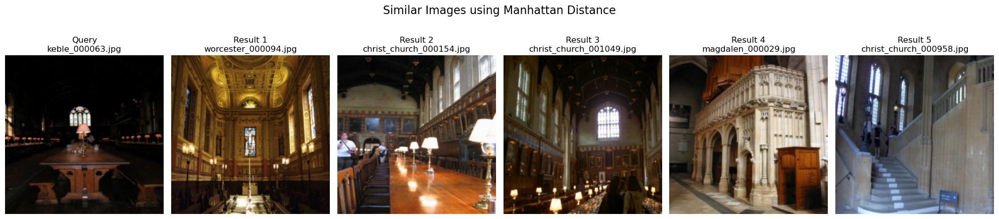

In [17]:
image_idx = 50

for metric in distance_metrics:
    similar_images = retrieve_similar_images(image_idx, metric, top_n=5)

    display_images(image_idx, similar_images, images, filenames, metric)

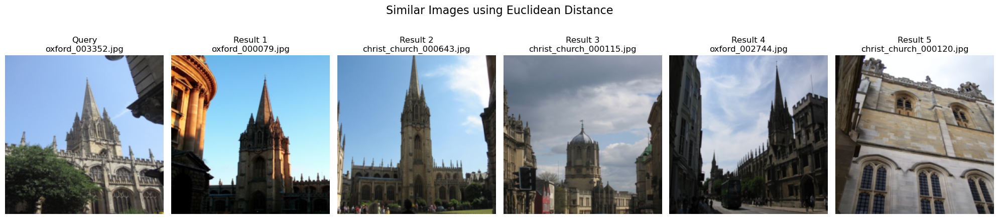

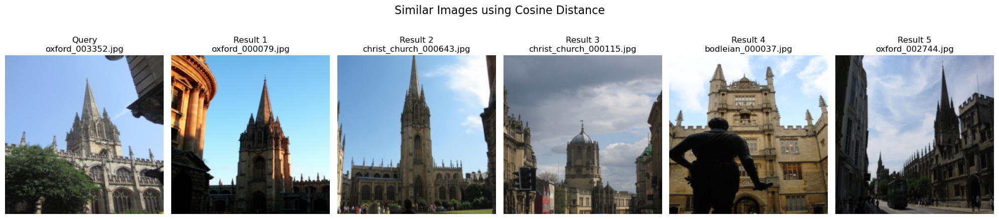

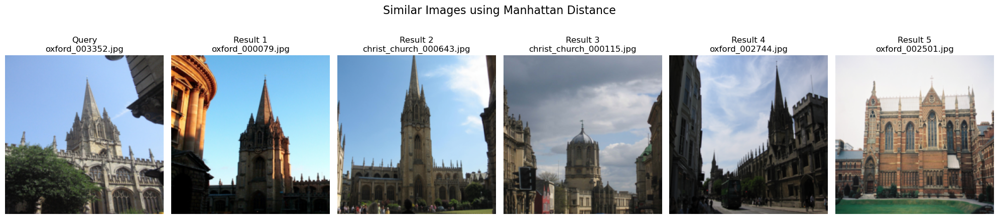

In [18]:
image_idx = 100

for metric in distance_metrics:
    similar_images = retrieve_similar_images(image_idx, metric, top_n=5)

    display_images(image_idx, similar_images, images, filenames, metric)